# Week 05 · Temporal-Difference Prediction — 시간차(TD) 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week05_model_free_prediction/02_td_prediction.ipynb)

슬라이드 **"Driving Home Example"**, **"Driving Home Example: MC vs. TD"**, **"Driving Home: The Numbers Behind the Arrows"**,
**"Bias/Variance Trade-Off"**, **"Random Walk Example"**, **"Random Walk: MC vs. TD"**, **"Batch MC and TD"**, **"AB Example"**,
**"AB Example: Working Out $V(A)$ and $V(B)$"**, **"Certainty Equivalence"** 를 재현합니다.
실제 리턴 $G_t$를 향해 가는 constant-$\alpha$ MC와, 다음 상태의 추정값을 이용하는 TD(0)를 같은 데이터에서 나란히 비교합니다
(S&B Figure 6.1, 예제 6.2, Figure 6.2, 예제 6.4).

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 노트북 전용
np.set_printoptions(precision=4, suppress=True, linewidth=120)
INK, MUTED = "#0b0b0b", "#52514e"

## 1. Driving Home (Driving Home Example, MC vs. TD, The Numbers Behind the Arrows)

퇴근길에 "집까지 남은 시간"을 계속 예측합니다. 상태의 가치 = **집까지 남은 예상 시간**, 각 구간의 보상 = **그 구간에 걸린 시간**,
$\gamma = 1$ 입니다. 슬라이드 표를 그대로 옮깁니다.

In [2]:
situations = ["leaving office", "reach car, raining", "exit highway", "behind truck", "home street", "arrive home"]
elapsed = np.array([0, 5, 20, 30, 40, 43])            # minutes since leaving the office
to_go = np.array([30, 35, 15, 10, 3, 0])              # predicted time to go = V(state)
total = elapsed + to_go                               # predicted total time
assert list(total) == [30, 40, 35, 40, 43, 43]        # last column of the slide table

print(f"{'State':20s} {'Elapsed':>8s} {'To go':>6s} {'Total':>6s}")
for name, e, v, tot in zip(situations, elapsed, to_go, total):
    print(f"{name:20s} {e:8d} {v:6d} {tot:6d}")

State                 Elapsed  To go  Total
leaving office              0     30     30
reach car, raining          5     35     40
exit highway               20     15     35
behind truck               30     10     40
home street                40      3     43
arrive home                43      0     43


$\alpha = 1$이면 갱신은 옛 예측을 목표값(target)으로 그냥 바꿔 놓는 것과 같습니다.

- MC 목표: 실제 남은 시간 $G_t$ (집에 도착해야 알 수 있음, 이번에는 총 43분)
- TD 목표: $R_{t+1} + V(S_{t+1})$ = 이번 구간 시간 + 다음 상태에서의 예측

In [3]:
V_old = to_go[:-1]                                    # states that get updated (not "arrive home")
R = np.diff(elapsed)                                  # leg times R_{t+1}
td_target = R + to_go[1:]                             # R_{t+1} + V(S_{t+1})
mc_target = elapsed[-1] - elapsed[:-1]                # actual time to go G_t
alpha = 1.0
td_change = alpha * (td_target - V_old)
mc_change = alpha * (mc_target - V_old)

def signed(v):
    return f"{v:+.0f}" if v != 0 else "0"


td_header = "TD target R+V(S')"
print(f"{'State':18s} {'V(old)':>6s} {'leg R':>6s} {td_header:>17s} {'MC target':>10s} {'TD / MC change':>15s}")
for i in range(5):
    td_text = f"{R[i]} + {to_go[i + 1]} = {td_target[i]}"
    change_text = f"{signed(td_change[i])} / {signed(mc_change[i])}"
    print(f"{situations[i][:18]:18s} {V_old[i]:6d} {R[i]:6d} {td_text:>17s} {mc_target[i]:10d} {change_text:>15s}")

# 슬라이드와 비교 (Lecture04.tex, "Driving Home: The Numbers Behind the Arrows")
slide = {"td_target": [40, 30, 20, 13, 3], "mc_target": [43, 38, 23, 13, 3],
         "td_change": [10, -5, 5, 3, 0], "mc_change": [13, 3, 8, 3, 0]}
for key, computed in [("td_target", td_target), ("mc_target", mc_target),
                      ("td_change", td_change), ("mc_change", mc_change)]:
    assert np.allclose(computed, slide[key]), key
print("\nAll 20 numbers match the slide table.")
print("S&B text: at 'exit highway' the MC error is", mc_change[2], "min; with alpha = 1/2 the update is",
      0.5 * mc_change[2], "min.")

State              V(old)  leg R TD target R+V(S')  MC target  TD / MC change
leaving office         30      5       5 + 35 = 40         43       +10 / +13
reach car, raining     35     15      15 + 15 = 30         38         -5 / +3
exit highway           15     10      10 + 10 = 20         23         +5 / +8
behind truck           10     10       10 + 3 = 13         13         +3 / +3
home street             3      3         3 + 0 = 3          3           0 / 0

All 20 numbers match the slide table.
S&B text: at 'exit highway' the MC error is 8.0 min; with alpha = 1/2 the update is 4.0 min.


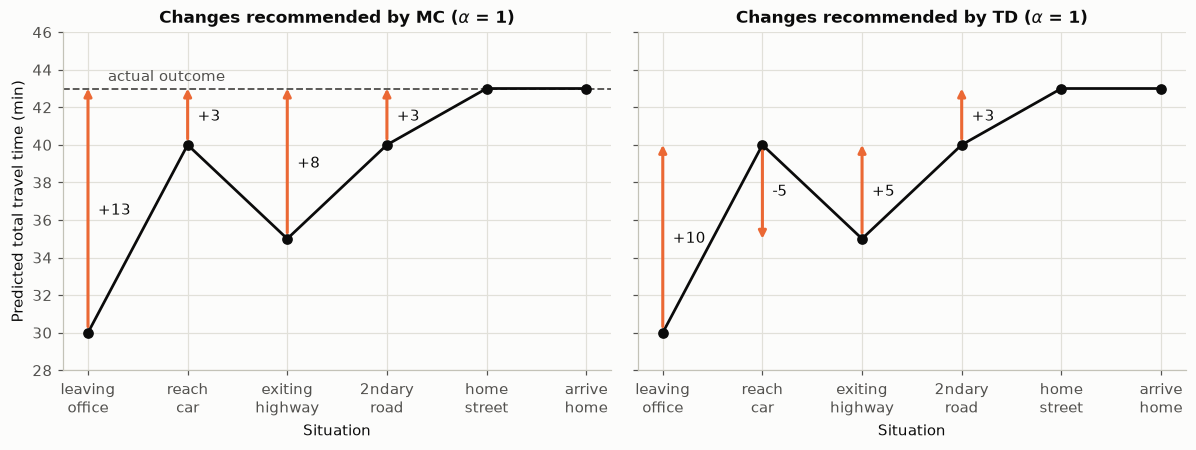

In [4]:
short = ["leaving\noffice", "reach\ncar", "exiting\nhighway", "2ndary\nroad", "home\nstreet", "arrive\nhome"]
x = np.arange(6)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, method in zip(axes, ("MC", "TD")):
    ax.plot(x, total, color=INK, marker="o", ms=6, lw=1.8, zorder=3)
    if method == "MC":
        ax.axhline(43, color=MUTED, ls="--", lw=1.2)
        ax.text(0.2, 43.4, "actual outcome", color=MUTED)
        targets, changes = np.full(5, 43), mc_change
    else:
        targets, changes = total[1:], td_change
    for i in range(5):
        if changes[i] != 0:
            ax.annotate("", xy=(x[i], targets[i]), xytext=(x[i], total[i]),
                        arrowprops=dict(arrowstyle="-|>", color=PALETTE[1], lw=2, shrinkA=4, shrinkB=0))
            ax.text(x[i] + 0.1, (total[i] + targets[i]) / 2, f"{changes[i]:+.0f}", color=INK, va="center")
    ax.set_xticks(x, short)
    ax.set_xlabel("Situation")
    ax.set_title(f"Changes recommended by {method} ($\\alpha$ = 1)")
    ax.set_ylim(28, 46)
axes[0].set_ylabel("Predicted total travel time (min)")
plt.tight_layout()
plt.show()

S&B Figure 6.1(슬라이드 "Driving Home Example: MC vs. TD")과 같은 그림입니다. MC(왼쪽)는 모든 상태를 하나의 최종 결과 43분 쪽으로 옮기며,
집에 도착하기 전에는 아무것도 갱신할 수 없습니다. TD(오른쪽)는 다음 예측과의 차이만 보므로, 고속도로가 예상보다 빨랐다는 것을 본 순간
"reach car"의 예측을 5분 **낮춥니다** — MC는 같은 상태를 3분 올립니다.

## 2. Random Walk (Random Walk Example, Random Walk: MC vs. TD)

S&B 예제 6.2: 상태 A–E, 가운데 C에서 시작, 매 단계 왼쪽/오른쪽으로 1/2 확률 이동. 오른쪽 끝에 도착하면 보상 $+1$, 나머지 보상 0,
$\gamma=1$. 모든 추정값을 $V(s)=0.5$로 초기화합니다.
참 가치는 "오른쪽으로 끝날 확률"이며, 벨만 방정식 $v = r + Pv$ 를 직접 풀어 $(1/6, \dots, 5/6)$ 임을 확인합니다.

In [5]:
LEFT_T, RIGHT_T, START = 0, 6, 3            # index 0 / 6 = terminals, 1..5 = A..E
NAMES = ["A", "B", "C", "D", "E"]

# true values from the Bellman equation (I - P) v = r over the 5 non-terminal states
P = np.zeros((5, 5))
r = np.zeros(5)
for i in range(5):
    for step in (-1, 1):
        j = i + step
        if 0 <= j < 5:
            P[i, j] = 0.5
        elif j == 5:
            r[i] += 0.5 * 1.0                 # stepping off the right end gives +1
v_true = np.linalg.solve(np.eye(5) - P, r)
TRUE_V = np.concatenate([[0.0], v_true, [0.0]])
print("true values A..E:", v_true)
assert np.allclose(v_true, np.arange(1, 6) / 6)


def generate_episode(rng):
    """States S_0..S_T (S_T terminal) and rewards R_1..R_T of one random walk."""
    s = START
    states, rewards = [s], []
    while s not in (LEFT_T, RIGHT_T):
        s = s + 1 if rng.random() < 0.5 else s - 1
        states.append(s)
        rewards.append(1.0 if s == RIGHT_T else 0.0)
    return states, rewards


def returns_of(rewards, gamma=1.0):
    """G_t for every t of an episode."""
    G = np.zeros(len(rewards))
    g = 0.0
    for t in reversed(range(len(rewards))):
        g = rewards[t] + gamma * g
        G[t] = g
    return G


def td0_update(V, states, rewards, alpha, gamma=1.0):
    """TD(0), online: V(S_t) += alpha * (R_{t+1} + gamma V(S_{t+1}) - V(S_t)) after every step.
    V may carry a leading axis (one row per alpha); terminal entries stay 0."""
    for t in range(len(rewards)):
        s, s_next = states[t], states[t + 1]
        V[..., s] += alpha * (rewards[t] + gamma * V[..., s_next] - V[..., s])


def mc_update(V, states, rewards, alpha, gamma=1.0):
    """Constant-alpha every-visit MC: after the episode, V(S_t) += alpha * (G_t - V(S_t))."""
    G = returns_of(rewards, gamma)
    for t in range(len(rewards)):
        s = states[t]
        V[..., s] += alpha * (G[t] - V[..., s])


def rms_error(V):
    """RMS error over the 5 non-terminal states (works on the last axis)."""
    return np.sqrt(np.mean((V[..., 1:6] - TRUE_V[1:6]) ** 2, axis=-1))

true values A..E: [0.1667 0.3333 0.5    0.6667 0.8333]


### 한 번의 실행: 0, 1, 10, 100 에피소드 후의 추정값 ($\alpha = 0.1$)

슬라이드 "Random Walk Example"의 두 그림(MC Prediction, TD(0) Prediction)처럼, **같은 에피소드 열**로 두 방법을 학습합니다.

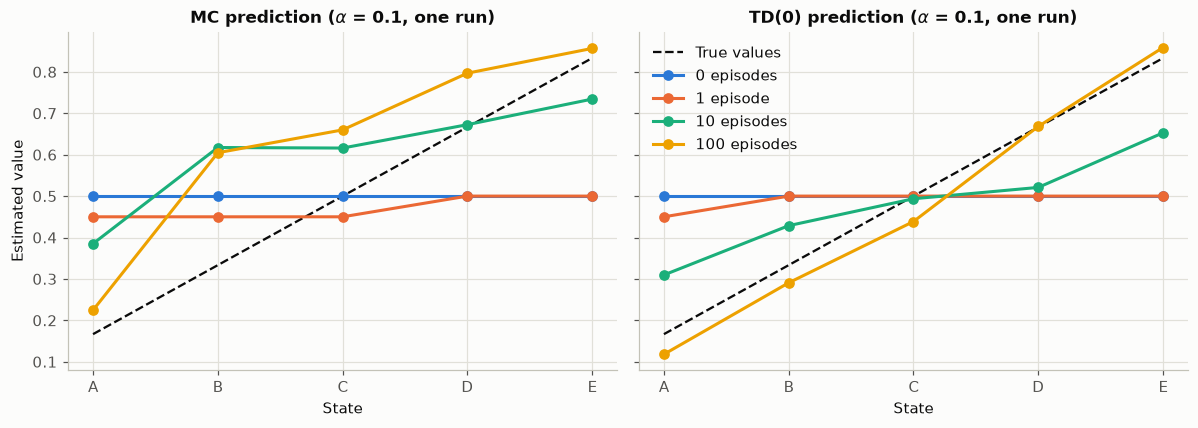

first episode: C -> B -> A -> T | reward 0.0
MC     values after 1 episode : [0.45 0.45 0.45 0.5  0.5 ]
TD(0)  values after 1 episode : [0.45 0.5  0.5  0.5  0.5 ]
TD(0) changed only state ['A'] by [-0.05]


In [6]:
def initial_V():
    V = np.full(7, 0.5)
    V[[LEFT_T, RIGHT_T]] = 0.0
    return V


rng = np.random.default_rng(4)
episodes = [generate_episode(rng) for _ in range(100)]
snapshots = {"MC": {}, "TD(0)": {}}
for method, update in (("MC", mc_update), ("TD(0)", td0_update)):
    V = initial_V()
    snapshots[method][0] = V.copy()
    for k, (states, rewards) in enumerate(episodes, start=1):
        update(V, states, rewards, alpha=0.1)
        if k in (1, 10, 100):
            snapshots[method][k] = V.copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, method in zip(axes, ("MC", "TD(0)")):
    ax.plot(range(5), TRUE_V[1:6], color=INK, lw=1.5, ls="--", label="True values")
    for color, k in zip(PALETTE, (0, 1, 10, 100)):
        ax.plot(range(5), snapshots[method][k][1:6], color=color, marker="o", ms=6, label=f"{k} episode" + ("" if k == 1 else "s"))
    ax.set_xticks(range(5), NAMES)
    ax.set_xlabel("State")
    ax.set_title(f"{method} prediction ($\\alpha$ = 0.1, one run)")
axes[0].set_ylabel("Estimated value")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

first = episodes[0]
print("first episode:", " -> ".join((["T"] + NAMES + ["T"])[s] for s in first[0]),
      "| reward", first[1][-1])
for method in ("MC", "TD(0)"):
    print(f"{method:6s} values after 1 episode :", snapshots[method][1][1:6])
changed = np.flatnonzero(~np.isclose(snapshots["TD(0)"][1], snapshots["TD(0)"][0]))
print("TD(0) changed only state", [NAMES[s - 1] for s in changed], "by",
      (snapshots["TD(0)"][1] - snapshots["TD(0)"][0])[changed])
assert len(changed) == 1 and np.isclose(abs(snapshots["TD(0)"][1] - snapshots["TD(0)"][0]).sum(), 0.05)

첫 에피소드 뒤 TD(0)는 **종료 직전의 한 상태만** $0.1 \times (0 \text{ 또는 } 1 - 0.5) = \pm 0.05$ 만큼 바뀝니다(S&B 연습문제 6.3).
다른 상태들의 TD 오차는 $0 + 0.5 - 0.5 = 0$이기 때문입니다. MC는 방문한 모든 상태를 실제 결과 쪽으로 옮깁니다(여러 번 방문한 상태는 여러 번).
에피소드 경로가 슬라이드의 실행과 다르므로 곡선 모양은 다르지만, 100 에피소드 후 TD 추정이 참 값에 더 가깝고 덜 들쭉날쭉한 경향은 같습니다.

### Bias/Variance: 목표값의 분산 (Bias/Variance Trade-Off)

참 가치 $v_\pi$를 알고 있을 때, 상태 C에서 두 목표값의 분산을 비교합니다. MC 목표 $G_t$는 에피소드 끝까지의 모든 무작위 이동에 의존하고,
TD 목표 $R_{t+1} + v_\pi(S_{t+1})$는 **한 번의** 이동에만 의존합니다.

In [7]:
rng = np.random.default_rng(5)
G_samples, td_samples = [], []
for _ in range(20_000):
    states, rewards = generate_episode(rng)            # every episode starts in C
    G_samples.append(returns_of(rewards)[0])
    td_samples.append(rewards[0] + TRUE_V[states[1]])
print(f"MC target  G_t              : mean {np.mean(G_samples):.3f}, variance {np.var(G_samples):.4f}  (exact 0.25)")
print(f"TD target  R + v_pi(S')     : mean {np.mean(td_samples):.3f}, variance {np.var(td_samples):.4f}  (exact 1/36 = {1/36:.4f})")
print(f"TD target  R + V(S'), V=0.5 : always 0.5 -> zero variance but biased as long as V(B), V(D) are wrong")

MC target  G_t              : mean 0.500, variance 0.2500  (exact 0.25)
TD target  R + v_pi(S')     : mean 0.500, variance 0.0278  (exact 1/36 = 0.0278)
TD target  R + V(S'), V=0.5 : always 0.5 -> zero variance but biased as long as V(B), V(D) are wrong


두 목표값 모두 평균은 $v_\pi(C)=0.5$(비편향)지만, TD 목표의 분산이 9배 작습니다. 실제 TD는 $v_\pi$ 대신 현재 추정값 $V$를 쓰므로
그만큼 **편향**이 생깁니다 — 이것이 슬라이드의 bias/variance trade-off입니다.

### RMS 오차 곡선 (Random Walk: MC vs. TD)

슬라이드 그림과 같은 $\alpha \in \{0.01, 0.02, 0.03, 0.04, 0.05, 0.1, 0.15\}$를 두 방법 모두에 사용하고, 책처럼 **100번의 실행**을 평균합니다.
(S&B 그림은 이 중 TD $\alpha = 0.05, 0.1, 0.15$와 MC $\alpha = 0.01, 0.02, 0.03, 0.04$만 보여 줍니다.)
모든 $\alpha$가 같은 에피소드를 쓰도록 $V$에 $\alpha$ 축을 두어 한꺼번에 갱신합니다.

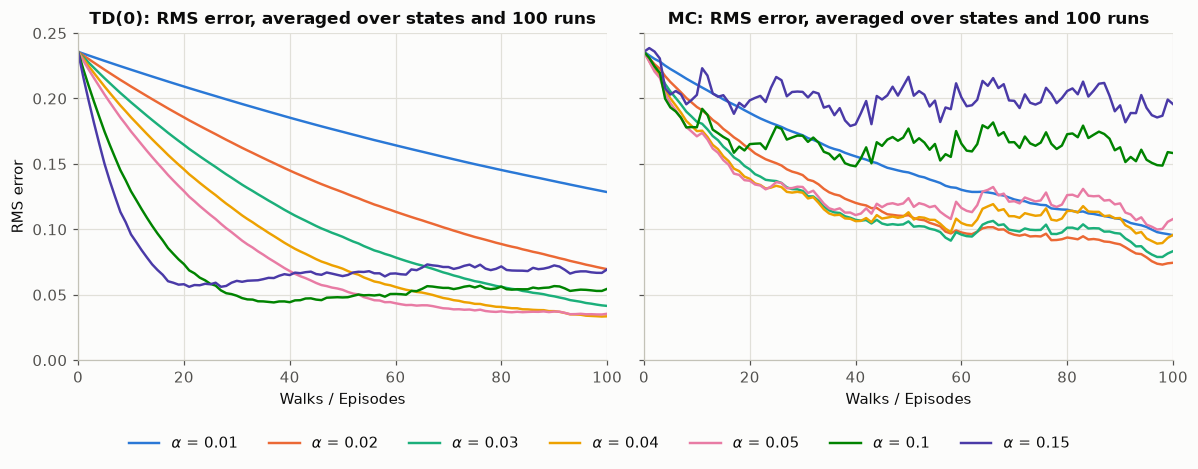

In [8]:
alphas = np.array([0.01, 0.02, 0.03, 0.04, 0.05, 0.1, 0.15])
n_runs, n_episodes = 100, 100
rms = {"TD(0)": np.zeros((n_runs, n_episodes + 1, len(alphas))),
       "MC": np.zeros((n_runs, n_episodes + 1, len(alphas)))}
rng = np.random.default_rng(6)
for run in range(n_runs):
    episodes = [generate_episode(rng) for _ in range(n_episodes)]
    for method, update in (("TD(0)", td0_update), ("MC", mc_update)):
        V = np.tile(initial_V(), (len(alphas), 1))     # one row per alpha
        rms[method][run, 0] = rms_error(V)
        for k, (states, rewards) in enumerate(episodes, start=1):
            update(V, states, rewards, alphas)
            rms[method][run, k] = rms_error(V)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, method in zip(axes, ("TD(0)", "MC")):
    mean_curve = rms[method].mean(axis=0)
    for i, a in enumerate(alphas):
        ax.plot(mean_curve[:, i], color=PALETTE[i], lw=1.6, label=f"$\\alpha$ = {a:g}")
    ax.set_title(f"{method}: RMS error, averaged over states and 100 runs")
    ax.set_xlabel("Walks / Episodes")
    ax.set_xlim(0, n_episodes)
    ax.set_ylim(0, 0.25)
axes[0].set_ylabel("RMS error")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(alphas), bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

### 슬라이드와 비교

시작점 RMS 오차는 계산으로 정확히 $\sqrt{1/18} = 0.236$ 이며 슬라이드 그림의 시작점과 같습니다. 나머지는 그림이므로 특징을 비교합니다.

In [9]:
final = {m: rms[m].mean(axis=0)[-1] for m in rms}
print(f"{'alpha':>6s} {'TD(0) @100':>11s} {'MC @100':>9s}")
for i, a in enumerate(alphas):
    print(f"{a:6g} {final['TD(0)'][i]:11.3f} {final['MC'][i]:9.3f}")
td_curve_015 = rms["TD(0)"].mean(axis=0)[:, -1]
print(f"\nstart RMS = {rms['TD(0)'][0, 0, 0]:.4f}  (sqrt(1/18) = {np.sqrt(1/18):.4f})")
print(f"TD alpha=0.15: minimum {td_curve_015.min():.3f} at episode {td_curve_015.argmin()}, then {td_curve_015[-1]:.3f} at 100")

assert np.isclose(rms["TD(0)"][0, 0, 0], np.sqrt(1 / 18))
assert final["TD(0)"].min() < final["MC"].min()                    # best TD beats best MC
assert td_curve_015.min() < td_curve_015[-1] - 0.005               # TD with large alpha: down, then up again

 alpha  TD(0) @100   MC @100
  0.01       0.128     0.096
  0.02       0.070     0.074
  0.03       0.041     0.083
  0.04       0.034     0.096
  0.05       0.035     0.108
   0.1       0.055     0.158
  0.15       0.069     0.196

start RMS = 0.2357  (sqrt(1/18) = 0.2357)
TD alpha=0.15: minimum 0.056 at episode 21, then 0.069 at 100


- 가장 좋은 TD(0) 곡선($\alpha \approx 0.05$)이 가장 좋은 MC 곡선보다 훨씬 낮습니다 — 슬라이드와 책의 결론과 같습니다.
- $\alpha$가 클수록 초반에 빠르게 내려가지만 더 높은 수준에서 멈춥니다. 상수 $\alpha$는 최근 에피소드에 계속 반응하므로 오차가 0으로 가지 않습니다.
- TD의 큰 $\alpha$(0.1, 0.15) 곡선은 내려갔다가 다시 **올라갑니다**(S&B 연습문제 6.5). 초기값(모두 0.5)에 따라 달라지는 현상으로, "직접 해보기" 1번에서 확인할 수 있습니다.
- 100 에피소드 시점의 값(TD $\alpha$=0.05 ≈ 0.035, TD $\alpha$=0.15 ≈ 0.07, MC $\alpha$=0.01 ≈ 0.10, MC $\alpha$=0.15 ≈ 0.2)도 슬라이드 그림과 거의 같습니다.

## 3. Batch MC and TD (Batch MC and TD, AB Example, Certainty Equivalence)

경험이 유한할 때, 같은 에피소드들을 **반복해서** 보여 주며 수렴할 때까지 학습하면(batch updating) 두 방법은 각각 하나의 답으로 수렴합니다.
S&B 6.3절처럼 모든 에피소드의 증분(increment)을 합한 뒤 한 번에 $V$를 바꾸고, 이를 반복합니다.

### AB Example

두 상태 A, B, 할인 없음, 8개의 에피소드: $A,0,B,0$ / $B,1$ ×6 / $B,0$.

In [10]:
A, B, T = 0, 1, 2                                   # T = terminal (value 0)
ab_episodes = [([A, B, T], [0.0, 0.0])] + [([B, T], [1.0])] * 6 + [([B, T], [0.0])]


def batch_update(episodes, V0, method, alpha=0.01, tol=1e-12, max_sweeps=100_000):
    """Batch updating: sum the increments of all episodes, then change V once; repeat until converged."""
    V = V0.astype(float).copy()
    for sweep in range(1, max_sweeps + 1):
        increment = np.zeros_like(V)
        for states, rewards in episodes:
            if method == "MC":
                G = returns_of(rewards)
                for t in range(len(rewards)):
                    increment[states[t]] += alpha * (G[t] - V[states[t]])
            else:  # TD(0)
                for t in range(len(rewards)):
                    s, s_next = states[t], states[t + 1]
                    increment[s] += alpha * (rewards[t] + V[s_next] - V[s])
        V += increment
        if np.abs(increment).max() < tol:
            return V, sweep
    raise RuntimeError("batch updating did not converge")


V_mc, sweeps_mc = batch_update(ab_episodes, np.zeros(3), "MC")
V_td, sweeps_td = batch_update(ab_episodes, np.zeros(3), "TD")
print(f"batch MC   : V(A) = {V_mc[A]:.4f}, V(B) = {V_mc[B]:.4f}   ({sweeps_mc} sweeps)")
print(f"batch TD(0): V(A) = {V_td[A]:.4f}, V(B) = {V_td[B]:.4f}   ({sweeps_td} sweeps)")

# 슬라이드와 비교 ("AB Example: Working Out V(A) and V(B)")
assert np.allclose([V_mc[A], V_mc[B]], [0.0, 0.75], atol=1e-6)
assert np.allclose([V_td[A], V_td[B]], [0.75, 0.75], atol=1e-6)
print("slide: MC V(A) = 0, TD V(A) = 0.75, both V(B) = 6/8 = 0.75  -> match")

batch MC   : V(A) = 0.0000, V(B) = 0.7500   (299 sweeps)
batch TD(0): V(A) = 0.7500, V(B) = 0.7500   (2277 sweeps)
slide: MC V(A) = 0, TD V(A) = 0.75, both V(B) = 6/8 = 0.75  -> match


슬라이드 "Batch MC and TD"는 "에피소드 $k \in [1, K]$를 반복해서 샘플링하고, 그 에피소드에 MC 또는 TD(0)를 적용"하는 방식으로 설명합니다.
이 방식(작은 $\alpha$의 온라인 갱신)도 같은 답 근처로 갑니다. 상수 $\alpha$라 약간 흔들리므로 마지막 5,000번의 평균을 봅니다.

In [11]:
rng = np.random.default_rng(7)
V_mc_s, V_td_s = np.zeros(3), np.zeros(3)
history_mc, history_td = [], []
for i in range(30_000):
    states, rewards = ab_episodes[rng.integers(len(ab_episodes))]
    mc_update(V_mc_s, states, rewards, alpha=0.01)
    td0_update(V_td_s, states, rewards, alpha=0.01)
    history_mc.append(V_mc_s[:2].copy())
    history_td.append(V_td_s[:2].copy())
avg_mc = np.mean(history_mc[-5000:], axis=0)
avg_td = np.mean(history_td[-5000:], axis=0)
print(f"sampled episodes, MC   : V(A) = {avg_mc[0]:.3f}, V(B) = {avg_mc[1]:.3f}")
print(f"sampled episodes, TD(0): V(A) = {avg_td[0]:.3f}, V(B) = {avg_td[1]:.3f}")
assert np.allclose(avg_mc, [0.0, 0.75], atol=0.05) and np.allclose(avg_td, [0.75, 0.75], atol=0.05)

sampled episodes, MC   : V(A) = 0.000, V(B) = 0.760
sampled episodes, TD(0): V(A) = 0.760, V(B) = 0.760


### Certainty Equivalence

두 답을 수렴 과정 없이 **직접** 구할 수 있습니다.

- Batch MC → 관측된 리턴과의 제곱오차 $\sum_k \sum_t (G_t^k - V(S_t^k))^2$ 를 최소화 = 상태별 **리턴의 평균**
- Batch TD(0) → 데이터에 가장 잘 맞는(최대 우도) 마르코프 모델 $\hat{\mathcal{P}}, \hat{\mathcal{R}}$ 을 만든 뒤 그 모델의 가치 = $\hat{\mathcal{R}} + \hat{\mathcal{P}} V$ 의 해

In [12]:
def mc_batch_solution(episodes, V0):
    """Every-visit average of the observed returns; unvisited states keep V0."""
    G_sum, G_cnt = np.zeros_like(V0), np.zeros_like(V0)
    for states, rewards in episodes:
        G = returns_of(rewards)
        for t in range(len(rewards)):
            G_sum[states[t]] += G[t]
            G_cnt[states[t]] += 1
    return np.where(G_cnt > 0, G_sum / np.maximum(G_cnt, 1), V0)


def certainty_equivalence(episodes, V0):
    """Solve V = R_hat + P_hat V for the maximum-likelihood model built from the data (gamma = 1)."""
    n = len(V0)
    N = np.zeros(n)                   # N(s): visits of s as a non-terminal state
    C = np.zeros((n, n))              # C(s, s'): observed transitions s -> s'
    R_sum = np.zeros(n)
    for states, rewards in episodes:
        for t in range(len(rewards)):
            N[states[t]] += 1
            C[states[t], states[t + 1]] += 1
            R_sum[states[t]] += rewards[t]
    seen = N > 0
    P_hat = C[seen] / N[seen, None]   # rows: visited states, columns: all states
    R_hat = R_sum[seen] / N[seen]
    V = V0.astype(float).copy()
    # (I - P_hat restricted to visited states) V_seen = R_hat + P_hat(to unvisited) V0 ; terminals have value 0
    A_mat = np.eye(seen.sum()) - P_hat[:, seen]
    b = R_hat + P_hat[:, ~seen] @ V0[~seen]
    V[seen] = np.linalg.solve(A_mat, b)
    return V, P_hat, R_hat


V_mc_cf = mc_batch_solution(ab_episodes, np.zeros(3))
V_td_cf, P_hat, R_hat = certainty_equivalence(ab_episodes, np.zeros(3))
print("ML model:  P_hat(A->B) =", P_hat[0, B], "  R_hat(A) =", R_hat[0], "  R_hat(B) =", R_hat[1])
print("closed form MC:", V_mc_cf[:2], "  closed form TD:", V_td_cf[:2])
assert np.allclose(V_mc_cf, V_mc, atol=1e-6) and np.allclose(V_td_cf, V_td, atol=1e-6)


def squared_error_on_data(V, episodes):
    """sum_k sum_t (G_t^k - V(S_t^k))^2 : how well V fits the observed returns."""
    return sum(((returns_of(r) - V[np.array(s[:-1])]) ** 2).sum() for s, r in episodes)


print(f"squared error on the 8 episodes:  MC solution {squared_error_on_data(V_mc_cf, ab_episodes):.4f}"
      f"  <  TD solution {squared_error_on_data(V_td_cf, ab_episodes):.4f}")

ML model:  P_hat(A->B) = 1.0   R_hat(A) = 0.0   R_hat(B) = 0.75
closed form MC: [0.   0.75]   closed form TD: [0.75 0.75]
squared error on the 8 episodes:  MC solution 1.5000  <  TD solution 2.0625


슬라이드의 값 $\hat{\mathcal{P}}_{AB} = 1$, $\hat{\mathcal{R}}_A = 0$, $V(A) = 0 + 0.75$ 가 그대로 나옵니다.
MC 해는 **이미 본 리턴**에 대한 제곱오차가 더 작지만(1.5 < 2.06), TD 해는 "A 다음엔 항상 B"라는 마르코프 구조를 이용하므로
**앞으로의 리턴**을 더 잘 예측할 가능성이 큽니다.

### Random walk under batch training (S&B Figure 6.2)

S&B 예제 6.3: 새 에피소드가 올 때마다 지금까지의 모든 에피소드를 batch로 삼아 수렴할 때까지 학습하고, RMS 오차(5개 상태, 100회 실행 평균)를 기록합니다.
수렴값은 위에서 확인한 대로 closed form과 같으므로 계산은 closed form으로 하고, 한 batch에서 반복 batch 갱신과 같은지 먼저 확인합니다.

In [13]:
rng = np.random.default_rng(8)
check_batch = [generate_episode(rng) for _ in range(20)]
for method, solver in (("MC", lambda eps: mc_batch_solution(eps, initial_V())),
                       ("TD", lambda eps: certainty_equivalence(eps, initial_V())[0])):
    V_iter, sweeps = batch_update(check_batch, initial_V(), method, alpha=0.002)
    print(f"{method}: iterative batch ({sweeps} sweeps) {V_iter[1:6]}  closed form {solver(check_batch)[1:6]}")
    assert np.allclose(V_iter, solver(check_batch), atol=1e-6)

MC: iterative batch (849 sweeps) [0.3077 0.5517 0.6863 0.8571 1.    ]  closed form [0.3077 0.5517 0.6863 0.8571 1.    ]


TD: iterative batch (2060 sweeps) [0.2087 0.4522 0.65   0.8125 0.9344]  closed form [0.2087 0.4522 0.65   0.8125 0.9344]

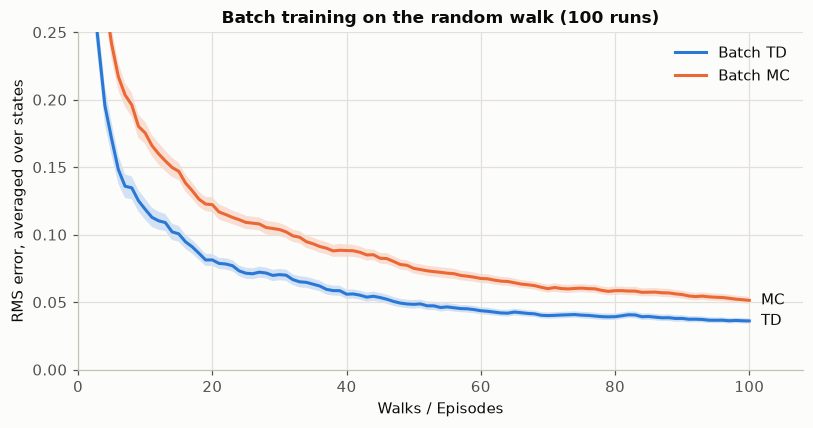

RMS after 10 / 50 / 100 episodes:
  batch TD: 0.119 / 0.048 / 0.036
  batch MC: 0.175 / 0.075 / 0.051


In [14]:
n_runs, n_episodes = 100, 100
batch_rms = {"TD": np.zeros((n_runs, n_episodes)), "MC": np.zeros((n_runs, n_episodes))}
rng = np.random.default_rng(9)
for run in range(n_runs):
    seen_episodes = []
    for k in range(n_episodes):
        seen_episodes.append(generate_episode(rng))
        batch_rms["MC"][run, k] = rms_error(mc_batch_solution(seen_episodes, initial_V()))
        batch_rms["TD"][run, k] = rms_error(certainty_equivalence(seen_episodes, initial_V())[0])

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(1, n_episodes + 1)
for method, color in (("TD", PALETTE[0]), ("MC", PALETTE[1])):
    m = batch_rms[method].mean(axis=0)
    se = batch_rms[method].std(axis=0) / np.sqrt(n_runs)
    ax.plot(x, m, color=color, label=f"Batch {method}")
    ax.fill_between(x, m - se, m + se, color=color, alpha=0.2, lw=0)
    ax.text(n_episodes + 1, m[-1], f" {method}", color=INK, va="center")
ax.set_xlabel("Walks / Episodes")
ax.set_ylabel("RMS error, averaged over states")
ax.set_title("Batch training on the random walk (100 runs)")
ax.set_xlim(0, n_episodes + 8)
ax.set_ylim(0, 0.25)
ax.legend()
plt.tight_layout()
plt.show()
print("RMS after 10 / 50 / 100 episodes:")
for method in ("TD", "MC"):
    m = batch_rms[method].mean(axis=0)
    print(f"  batch {method}: {m[9]:.3f} / {m[49]:.3f} / {m[99]:.3f}")
assert (batch_rms["TD"].mean(axis=0)[4:] < batch_rms["MC"].mean(axis=0)[4:]).all()

S&B Figure 6.2와 같이 batch TD가 batch MC보다 계속 낮습니다. 리턴의 평균(MC)은 "관측한 데이터"에 대해서는 최적이지만,
마르코프 과정에서는 최대 우도 모델에서 계산한 값(TD, certainty-equivalence 추정)이 참 가치에 더 가깝습니다.
이것이 슬라이드 "Advantages and Disadvantages of MC and TD (3)"의 "TD exploits Markov property"입니다.

## 직접 해보기

1. RMS 곡선 실험에서 초기값을 `V = 0.5` 대신 0으로 바꿔 보세요. TD의 큰 $\alpha$ 곡선이 "내려갔다 다시 올라가는" 현상이 사라지나요? (S&B 연습문제 6.5)
2. AB 예제에 에피소드 `([A, T], [1.0])`를 몇 개 추가해 보세요. A에서 B를 거치지 않는 경로가 생기면 $\hat{\mathcal{P}}$와 두 방법의 $V(A)$가 어떻게 바뀌나요?
3. Driving home에서 $\alpha = 0.5$로 바꿔 두 그림의 화살표 길이가 어떻게 되는지 확인하고, 둘째 날 "고속도로에서 25분 정체"가 생긴 경우 TD가 언제부터 예측을 고칠 수 있는지 생각해 보세요.
4. Random walk의 상태 수를 19개로 늘리면(다음 노트북의 설정) 최적 $\alpha$와 MC/TD의 차이가 어떻게 변하는지 RMS 곡선으로 비교해 보세요.